<a href="https://colab.research.google.com/github/jess22jess/SIMULACI-N-II/blob/main/Black_Scholes_Colab_con_Graficas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ACTIVIDAD 4: Ecuación de Black and Scholes
Arcos Gutiérrez Jessica Beatriz

Gómez Guzmán María Fernanda

---

##1. Sustituimos con los datos de el Ejercicio 5 en la ecuación 1)
Anota la ecuación numérica y la condición terminal. S y t siguen siendo variables.

In [19]:
import sympy as sy
from IPython.display import display
sy.init_printing()

Definimos las variables

In [20]:
S = sy.symbols('S', positive=True)
t = sy.symbols('t', real=True)
x = sy.symbols('x', real=True)
tau = sy.symbols('tau', positive=True)
sigma, r, q = sy.symbols('sigma r q')
R = sy.Rational

Parámetros

In [21]:
T, E, S0 = R('0.3'), 60, R('58.5')
datos = {sigma: R('0.29'), r: R('0.04'), q: 0}

Coeficientes auxiliares de la EDP evaluados en los parámetros del ejercicio

In [22]:
A = (sigma**2/2).subs(datos)
b = (r-q).subs(datos)
rr = r.subs(datos)

Formulación de la EDP de Black-Scholes (Ecuación 1) y condición terminal

In [23]:
V = sy.Function('V')(S,t)
P = sy.diff(V,t)+sigma**2/2*S**2*sy.diff(V,S,2)+(r-q)*S*sy.diff(V,S)-r*V
P = P.subs(datos)

Despliegue simbólico de la EDP y del payoff al vencimiento V(S, T) = (S - E)+

In [24]:
display(sy.Eq(P,0).evalf(10))
display(sy.Eq(V.subs(t,T),sy.Max(S-E,0)))

            2                                                                
         2 ∂                     ∂                            ∂              
0.04205⋅S ⋅───(V(S, t)) + 0.04⋅S⋅──(V(S, t)) - 0.04⋅V(S, t) + ──(V(S, t)) = 0
             2                   ∂S                           ∂t             
           ∂S                                                                

V(S, 3/10) = Max(0, S - 60)

## 2. Cambio temporal: tau = T - t
Anota las derivadas y la ecuación resultante.

Paso 1: Inversión de la variable temporal (tau = T - t)

In [25]:
W = sy.Function('W')                    # Nueva función incógnita en términos de (S, tau)
Wt = W(S, T - t)                        # Definición explícita V(S, t) = W(S, T - t)

Verificación simbólica de la regla de la cadena para las derivadas de V respecto a t y S

In [26]:
for D in [sy.diff(Wt, t), sy.diff(Wt, S), sy.diff(Wt, S, 2)]:
    display(D)

 ⎛ ∂           ⎞│           
-⎜───(W(S, ξ₂))⎟│           
 ⎝∂ξ₂          ⎠│ξ₂=3/10 - t

∂                 
──(W(S, 3/10 - t))
∂S                

 2                 
∂                  
───(W(S, 3/10 - t))
  2                
∂S                 

Sustitución de derivadas en la EDP (como d(tau)/dt = -1, entonces dV/dt = -dW/dtau)

Se multiplica por -1 y se expande para dejar positivo el coeficiente de dW/dtau

In [27]:
P1 = sy.expand(
    -P.xreplace({
        sy.diff(V, t): -sy.diff(W(S, tau), tau),
        sy.diff(V, S): sy.diff(W(S, tau), S),
        sy.diff(V, S, 2): sy.diff(W(S, tau), S, 2),
        V: W(S, tau),
    })
)

EDP transformada y la nueva condición inicial en tau = 0

In [28]:
display(sy.Eq(P1,0).evalf(10))
display(sy.Eq(W(S,0),sy.Max(S-E,0)))

              2                                                                
           2 ∂                     ∂                            ∂              
- 0.04205⋅S ⋅───(W(S, τ)) - 0.04⋅S⋅──(W(S, τ)) + 0.04⋅W(S, τ) + ──(W(S, τ)) = 0
               2                   ∂S                           ∂τ             
             ∂S                                                                

W(S, 0) = Max(0, S - 60)

## 3. Cambio logarítmico: x = ln(S)
Anota las dos derivadas espaciales y la ecuación simplificada.

Paso 2: Transformación logarítmica del precio subyacente (x = ln S, S = e^x)

In [29]:
Z = sy.Function('Z')                    # Nueva función incógnita en términos de (x, tau)
Wlog = Z(sy.log(S), tau)                # Relación W(S, tau) = Z(ln S, tau)

Cálculo de la primera y segunda derivada respecto a S por regla de la cadena

In [30]:
display(sy.diff(Wlog, S))
display(sy.factor(sy.diff(Wlog, S, 2)))

⎛ ∂           ⎞│         
⎜───(Z(ξ₁, τ))⎟│         
⎝∂ξ₁          ⎠│ξ₁=log(S)
─────────────────────────
            S            

                              ⎛  2           ⎞│         
  ⎛ ∂           ⎞│            ⎜ ∂            ⎟│         
- ⎜───(Z(ξ₁, τ))⎟│          + ⎜────(Z(ξ₁, τ))⎟│         
  ⎝∂ξ₁          ⎠│ξ₁=log(S)   ⎜   2          ⎟│         
                              ⎝∂ξ₁           ⎠│ξ₁=log(S)
────────────────────────────────────────────────────────
                            2                           
                           S                            

Sustitución de W(S, tau) por Z(ln S, tau) en la EDP, evaluación de derivadas (.doit()) y cambio de variable S = e^x para eliminar los coeficientes variables en S

In [31]:
P2 = sy.simplify(P1.subs(W(S, tau), Wlog).doit().subs(S, sy.exp(x)))
P2 = sy.expand(P2)                      # Expansión para separar cada término diferencial

EDP de coeficientes constantes y la condición inicial Z(x, 0) = (e^x - E)+

In [32]:
display(sy.Eq(P2,0).evalf(10))
display(sy.Eq(Z(x,0),sy.Max(sy.exp(x)-E,0)))

                                                            2              
               ∂                     ∂                     ∂               
0.04⋅Z(x, τ) + ──(Z(x, τ)) + 0.00205⋅──(Z(x, τ)) - 0.04205⋅───(Z(x, τ)) = 0
               ∂τ                    ∂x                      2             
                                                           ∂x              

Z(x, 0) = Max(0, exp(x) - 60)

## 4. Cambio exponencial y ecuación del calor


Paso 3: Eliminación de términos de orden inferior mediante cambio exponencial

In [33]:
alpha, beta = sy.symbols('alpha beta')
u = sy.Function('u')(x, tau)              # Función incógnita de la ecuación del calor
Zexp = sy.exp(-alpha * x - beta * tau) * u  # Sustitución Z(x, tau) = e^(-alpha*x - beta*tau) u(x, tau)

Cálculo y factorización de las derivadas parciales de Z respecto a tau y x

In [34]:
for D in [sy.diff(Zexp, tau), sy.diff(Zexp, x), sy.diff(Zexp, x, 2)]:
    display(sy.factor(D))

⎛             ∂          ⎞  -α⋅x  -β⋅τ
⎜-β⋅u(x, τ) + ──(u(x, τ))⎟⋅ℯ    ⋅ℯ    
⎝             ∂τ         ⎠            

⎛             ∂          ⎞  -α⋅x  -β⋅τ
⎜-α⋅u(x, τ) + ──(u(x, τ))⎟⋅ℯ    ⋅ℯ    
⎝             ∂x         ⎠            

⎛                                2          ⎞            
⎜ 2               ∂             ∂           ⎟  -α⋅x  -β⋅τ
⎜α ⋅u(x, τ) - 2⋅α⋅──(u(x, τ)) + ───(u(x, τ))⎟⋅ℯ    ⋅ℯ    
⎜                 ∂x              2         ⎟            
⎝                               ∂x          ⎠            

Sustitución en la EDP P2 y multiplicación por e^(alpha * x + beta * tau) para cancelar la exponencial

In [35]:
P3 = sy.expand(
    sy.simplify(P2.subs(Z(x, tau), Zexp).doit() * sy.exp(alpha * x + beta * tau))
)
display(sy.Eq(P3, 0).evalf(10))

                                                                               ↪
           2                                        ∂                          ↪
- 0.04205⋅α ⋅u(x, τ) - 0.00205⋅α⋅u(x, τ) + 0.0841⋅α⋅──(u(x, τ)) - β⋅u(x, τ) +  ↪
                                                    ∂x                         ↪
                                                                               ↪

↪                                                             2              
↪                ∂                     ∂                     ∂               
↪ 0.04⋅u(x, τ) + ──(u(x, τ)) + 0.00205⋅──(u(x, τ)) - 0.04205⋅───(u(x, τ)) = 0
↪                ∂τ                    ∂x                      2             
↪                                                            ∂x              

Extracción de los coeficientes de du/dx (c1) y de u (c0) para igualarlos a cero

In [36]:
c1 = P3.coeff(sy.diff(u, x))
c0 = P3.coeff(u)
display(sy.Eq(c1, 0).evalf(10))
display(sy.Eq(c0, 0).evalf(10))

0.0841⋅α + 0.00205 = 0

           2                           
- 0.04205⋅α  - 0.00205⋅α - β + 0.04 = 0

Hallar alpha y beta

In [37]:
sol = sy.solve([c1, c0], [alpha, beta], dict=True)[0]
for p in [alpha, beta]:
    display(sy.Eq(p, sol[p]).evalf(10))

α = -0.02437574316

β = 0.04002498514

Almacenamiento de los valores obtenidos y verificación de la ecuación del calor resultante

In [38]:
a, B = sol[alpha],sol[beta]
display(sy.Eq(P3.subs(sol).simplify(),0).evalf(10))

                       2              
∂                     ∂               
──(u(x, τ)) - 0.04205⋅───(u(x, τ)) = 0
∂τ                      2             
                      ∂x              

## 5. Fórmula de Green y regreso a V
La integral se evalúa completando cuadrados. Se usa la expresión equivalente con erf.

In [39]:
s = sy.symbols('s', real=True)
v = 2 * A * tau

Integral de Green para u(x, tau) con condición inicial u(s, 0) = e^(alpha*s) * (e^s - E)+

El límite inferior se trunca en s = ln(E), pues para s < ln(E) el payoff de la call es 0

In [40]:
I = sy.Integral(
    sy.exp(-(x - s)**2 / (2 * v) + a * s) * (sy.exp(s) - E) / sy.sqrt(2 * sy.pi * v),
    (s, sy.log(E), sy.oo),
)
display(sy.Eq(u, I))

             ∞                                               
             ⌠                                               
             ⎮                                           2   
             ⎮                       41⋅s   5000⋅(-s + x)    
             ⎮                     - ──── - ──────────────   
             ⎮          ⎛ s     ⎞    1682       841⋅τ        
             ⎮    50⋅√2⋅⎝ℯ  - 60⎠⋅ℯ                          
u(x, τ) =    ⎮    ──────────────────────────────────────── ds
             ⎮                    29⋅√π⋅√τ                   
             ⌡                                               
          log(60)                                            

Definición de la función de distribución acumulada normal estándar N(z) vía erf

Función auxiliar J(c): resuelve analíticamente la integral del núcleo gaussiano multiplicado por exp(c*s) en el intervalo [ln(E), infinito) completando el cuadrado

In [41]:
N = lambda z: (1 + sy.erf(z / sy.sqrt(2))) / 2

In [42]:
J = lambda c: sy.exp(c * x + c**2 * v / 2) * N((x + c * v - sy.log(E)) / sy.sqrt(v))

Evaluación explícita de u(x, tau) = J(alpha + 1) - E * J(alpha)

In [43]:
u_sol = J(a + 1) - E * J(a)

In [44]:
V_green = sy.exp(-a * x - B * tau) * u_sol

Regreso a las variables financieras originales (S = e^x, tau = T - t) y definición de d1, d2

In [45]:
D1 = (sy.log(S / E) + (b + A) * tau) / sy.sqrt(v)
D2 = D1 - sy.sqrt(v)
C = S * N(D1) - E * sy.exp(-rr * tau) * N(D2)

Expresiones simbólicas de d1 y d2

In [46]:
display(sy.Eq(sy.Symbol('d_1'),D1))
display(sy.Eq(sy.Symbol('d_2'),D2))

         ⎛1641⋅τ      ⎛S ⎞⎞
     100⋅⎜────── + log⎜──⎟⎟
         ⎝20000       ⎝60⎠⎠
d₁ = ──────────────────────
             29⋅√τ         

                   ⎛1641⋅τ      ⎛S ⎞⎞
               100⋅⎜────── + log⎜──⎟⎟
       29⋅√τ       ⎝20000       ⎝60⎠⎠
d₂ = - ───── + ──────────────────────
        100            29⋅√τ         

## 6. Evaluación final en S = 58.5, t = 0
Anota d1, d2, las probabilidades y el precio. Se comprueba también la integral de Green.

In [47]:
punto = {S: S0, tau: T}

Cálculo de d1, d2, N(d1), N(d2) y el precio V

In [48]:
for nombre, expr in [('d1', D1), ('d2', D2), ('N(d1)', N(D1)), ('N(d2)', N(D2)), ('V', C)]:
    print(nombre, '=', expr.subs(punto).evalf(12))

d1 = -0.00442464122518
d2 = -0.163264182902
N(d1) = 0.498234829299
N(d2) = 0.435155216691
V = 3.34886389501


Evaluación directa desde la solución integral de Green

In [49]:
precio_green = V_green.subs({x: sy.log(S0), tau: T}).evalf(12)
print('Precio por Green =', precio_green)

Precio por Green = 3.34886389501


Comprobación numérica

In [50]:
assert abs(float(precio_green-C.subs(punto).evalf()))<1e-10

## 7. Payoff de la opción call al vencimiento
Anota: al vencimiento, el valor es cero si S ≤ 60 y S − 60 si S > 60.

In [51]:
import numpy as np
import matplotlib.pyplot as plt

Visualización gráfica del payoff al vencimiento V(S, T) = max(S - E, 0)

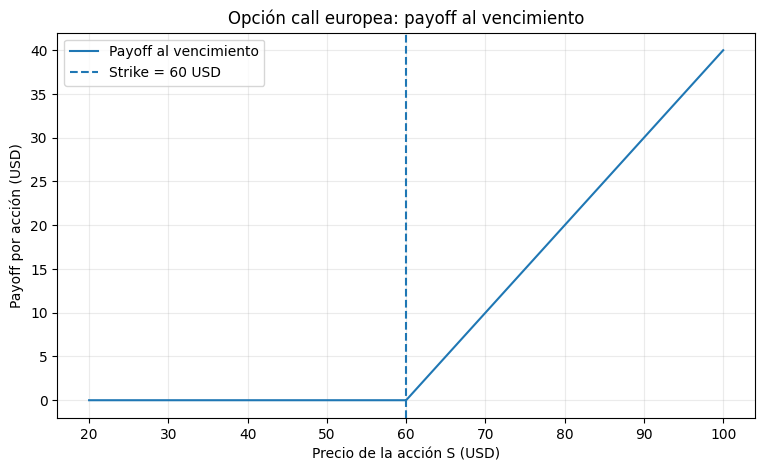

In [52]:
precios = np.linspace(20, 100, 500)
payoff = np.maximum(precios-float(E), 0)

plt.figure(figsize=(9,5))
plt.plot(precios, payoff, label='Payoff al vencimiento')
plt.axvline(float(E), linestyle='--', label='Strike = 60 USD')
plt.xlabel('Precio de la acción S (USD)')
plt.ylabel('Payoff por acción (USD)')
plt.title('Opción call europea: payoff al vencimiento')
plt.grid(alpha=.25)
plt.legend()
plt.show()

## 8. Precio actual de la opción según Black-Scholes
Anota: el precio de la call aumenta con S. Para S = 58.5, el valor se obtiene de la solución analítica, no de una simulación aleatoria.

In [53]:
from scipy.special import erf

Visualización gráfica del precio actual de la opción V(S, 0) según Black-Scholes

In [54]:
call = sy.lambdify(S, C.subs(tau, T), modules=[{'erf': erf}, 'numpy']) # Convierte C(S) a función vectorizada
valores = call(precios)                                                 # Evalúa la curva de Black-Scholes en t = 0
precio_ibm = float(C.subs(punto).evalf())                               # Precio puntual de la call para IBM

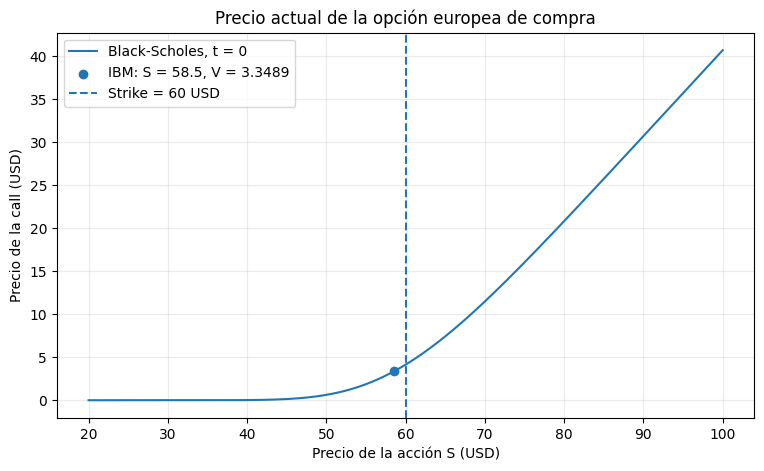

In [55]:
plt.figure(figsize=(9,5))
plt.plot(precios, valores, label='Black-Scholes, t = 0')
plt.scatter([float(S0)], [precio_ibm], zorder=5,
            label=f'IBM: S = 58.5, V = {precio_ibm:.4f}')
plt.axvline(float(E), linestyle='--', label='Strike = 60 USD')
plt.xlabel('Precio de la acción S (USD)')
plt.ylabel('Precio de la call (USD)')
plt.title('Precio actual de la opción europea de compra')
plt.grid(alpha=.25)
plt.legend()
plt.show()

## 9. Comparación: precio actual y payoff al vencimiento
Anota: aunque S = 58.5 es menor que E = 60, la call tiene un precio positivo antes del vencimiento por la posibilidad de que la acción supere el strike.

Comparativa gráfica: precio actual en t = 0 frente al payoff al vencimiento

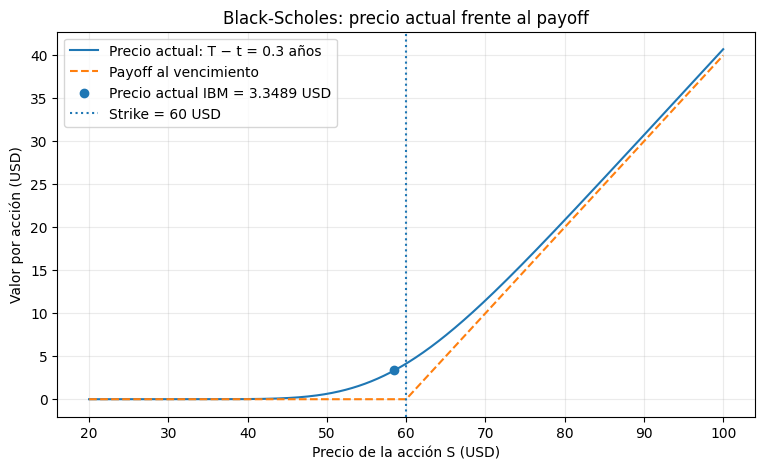

In [56]:
plt.figure(figsize=(9, 5))
plt.plot(precios, valores, label='Precio actual: T − t = 0.3 años')          # Curva de Black-Scholes
plt.plot(precios, payoff, linestyle='--', label='Payoff al vencimiento')    # Límite intrínseco en t = T
plt.scatter([float(S0)], [precio_ibm], zorder=5,
            label=f'Precio actual IBM = {precio_ibm:.4f} USD')
plt.axvline(float(E), linestyle=':', label='Strike = 60 USD')
plt.xlabel('Precio de la acción S (USD)')
plt.ylabel('Valor por acción (USD)')
plt.title('Black-Scholes: precio actual frente al payoff')
plt.grid(alpha=.25)
plt.legend()
plt.show()

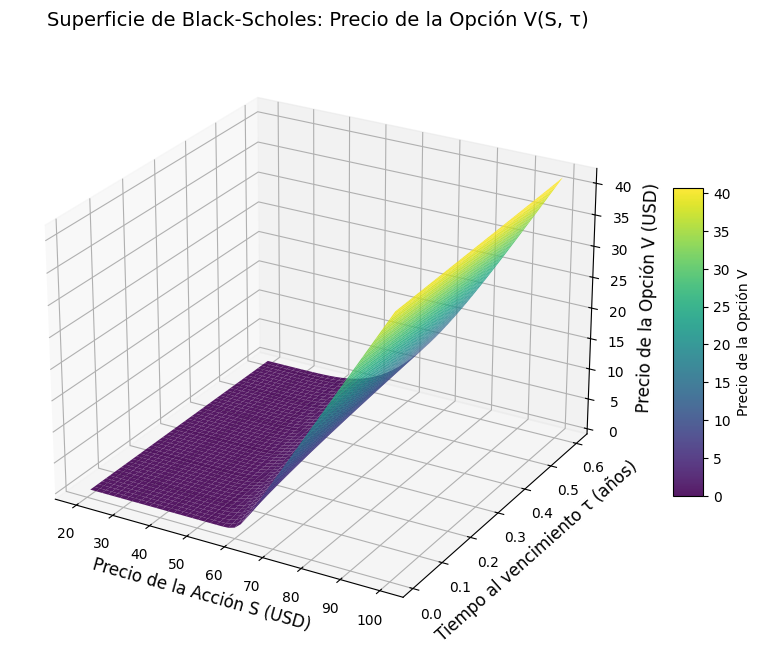

In [58]:
from mpl_toolkits.mplot3d import Axes3D

# Superficie 3D del precio de la opción V(S, tau) en función de S y tau
S_3d = np.linspace(20, 100, 50)            # Rango de precios del subyacente
tau_3d = np.linspace(0.01, 0.6, 50)       # Rango de tiempo al vencimiento
S_mesh, tau_mesh = np.meshgrid(S_3d, tau_3d)

V_3d_func = sy.lambdify((S, tau), C, modules=[{'erf': erf}, 'numpy']) # Función 3D vectorizada
V_mesh = V_3d_func(S_mesh, tau_mesh)

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(S_mesh, tau_mesh, V_mesh, cmap='viridis', edgecolor='none', alpha=0.9)
fig.colorbar(surf, shrink=0.5, aspect=10, label='Precio de la Opción V')

ax.set_title('Superficie de Black-Scholes: Precio de la Opción V(S, τ)', fontsize=14)
ax.set_xlabel('Precio de la Acción S (USD)', fontsize=12)
ax.set_ylabel('Tiempo al vencimiento τ (años)', fontsize=12)
ax.set_zlabel('Precio de la Opción V (USD)', fontsize=12)
ax.view_init(elev=25, azim=-60)

plt.show()